In [1]:
import pandas as pd
delivery = pd.read_csv('delivery_data.csv')
delivery.head()

,Distance_km,Prep_Time_min,Courier_Experience_yrs,Weather,Traffic_Level,Vehicle_Type,Delivery_Time_min,Is_Late
0,5.993428,11.624109,7,NaN,High,Scooter,44.013542,0
1,4.723471,14.277407,2,Sunny,High,Car,35.527712,0
2,6.295377,11.037900,9,Rainy,High,Scooter,48.567934,1
3,8.046060,13.460192,7,Sunny,High,Car,50.452710,1
4,4.531693,5.531927,7,Rainy,Medium,Bicycle,47.632817,1


In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [3]:
X = delivery.drop('Is_Late',axis=1)
y = delivery['Is_Late']

In [4]:
numeric_features = X.select_dtypes(include=['int64','float64']).columns
categori_features = X.select_dtypes(include=['str']).columns

In [5]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

In [6]:
numerical_transformer = Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='mean')),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('scaler', StandardScaler())
])

In [7]:
categorical_transformer = Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('onehot',OneHotEncoder(handle_unknown='ignore')) 
])

In [8]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer,numeric_features),
        ('cat',categorical_transformer,categori_features)
    ],
    remainder='passthrough'
)

In [9]:
from sklearn.model_selection import train_test_split
Xtrain,Xtest,ytrain,ytest = train_test_split(X,y, random_state=1)

In [10]:
models1 = LogisticRegression(max_iter=1000)
models2 = RandomForestClassifier()
models3 = SVC()

In [11]:
from sklearn.metrics import accuracy_score

In [26]:
pipeline1 = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier' , models1)
])
pipeline1.fit(Xtrain,ytrain)
y_pred1 = pipeline1.predict(Xtest)
accuracy = accuracy_score(ytest,y_pred1)
accuracy

0.974

In [27]:
pipeline2 = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier' , models2)
])
pipeline2.fit(Xtrain,ytrain)
y_pred2 = pipeline2.predict(Xtest)
accuracy = accuracy_score(ytest,y_pred2)
accuracy

1.0

In [28]:
pipeline3 = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier' , models3)
])
pipeline3.fit(Xtrain,ytrain)
y_pred3 = pipeline3.predict(Xtest)
accuracy = accuracy_score(ytest,y_pred3)
accuracy

0.96

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix,precision_score,recall_score

In [ ]:
precision1 = precision_score(ytest,y_pred1)
precision1

0.9816849816849816

In [31]:
precision2 = precision_score(ytest,y_pred2)
precision2

1.0

In [32]:
precision3 = precision_score(ytest,y_pred3)
precision3

0.9539007092198581

In [33]:
recall1 = recall_score(ytest,y_pred1)
recall1

0.9710144927536232

In [34]:
recall2 = recall_score(ytest,y_pred2)
recall2

1.0

In [35]:
recall3 = recall_score(ytest,y_pred3)
recall3

0.9746376811594203

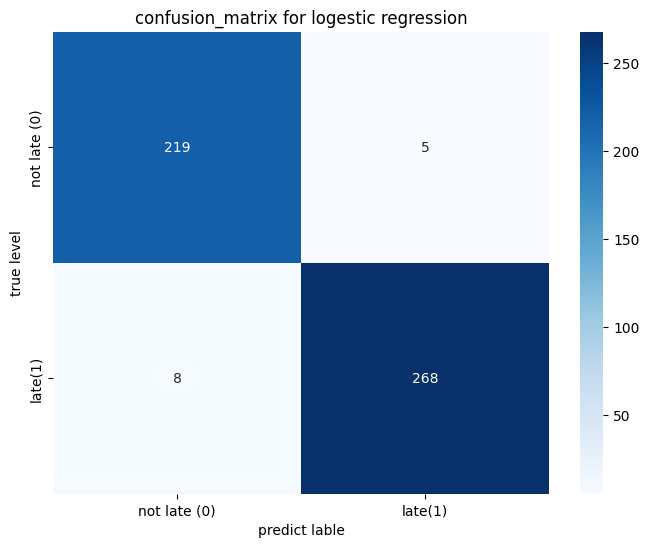

In [36]:
confusion_matrixs1 = confusion_matrix(ytest,y_pred1)
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrixs1 , annot=True , fmt='d' , cmap='Blues',
            xticklabels=['not late (0)', 'late(1)'],
            yticklabels=['not late (0)', 'late(1)'])
plt.title('confusion_matrix for logestic regression')
plt.xlabel('predict lable')
plt.ylabel('true level')
plt.show()

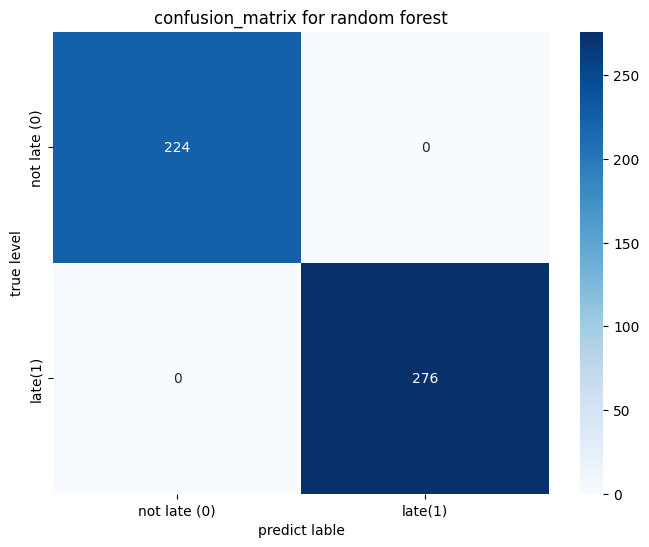

In [37]:
confusion_matrixs2 = confusion_matrix(ytest,y_pred2)
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrixs2 , annot=True , fmt='d' , cmap='Blues',
            xticklabels=['not late (0)', 'late(1)'],
            yticklabels=['not late (0)', 'late(1)'])
plt.title('confusion_matrix for random forest')
plt.xlabel('predict lable')
plt.ylabel('true level')
plt.show()

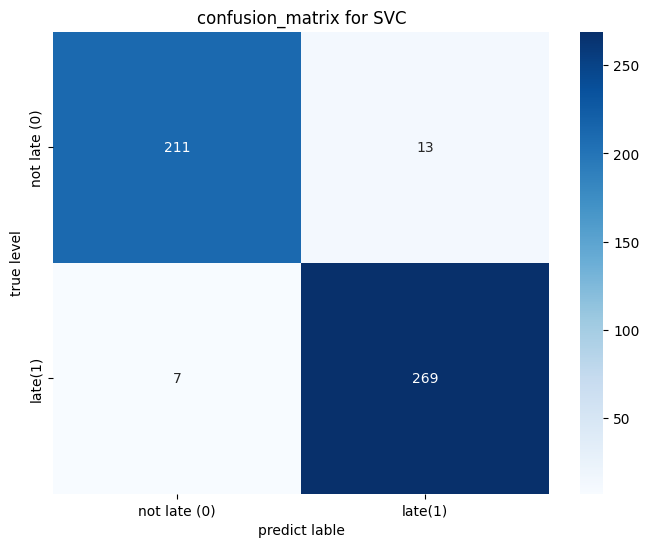

In [39]:
confusion_matrixs3 = confusion_matrix(ytest,y_pred3)
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrixs3 , annot=True , fmt='d' , cmap='Blues',
            xticklabels=['not late (0)', 'late(1)'],
            yticklabels=['not late (0)', 'late(1)'])
plt.title('confusion_matrix for SVC')
plt.xlabel('predict lable')
plt.ylabel('true level')
plt.show()